In [4]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Connect to local GPU and configure dynamic memory growth
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"Connected to local GPU: {gpus[0].name}")
    except RuntimeError as e:
        print("GPU configuration warning:", e)
else:
    print("No GPU detected, running on CPU.")

# Load Fashion-MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

Connected to local GPU: /physical_device:GPU:0


W0000 00:00:1792037162.759473  309012 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


In [5]:
print("Training data:", x_train.shape)
print("Training labels:", y_train.shape)

print("Testing data:", x_test.shape)
print("Testing labels:", y_test.shape)

print("Pixel values:", x_train.min(), "to", x_train.max())
print("First 10 labels:", y_train[:10])

Training data: (60000, 28, 28)
Training labels: (60000,)
Testing data: (10000, 28, 28)
Testing labels: (10000,)
Pixel values: 0 to 255
First 10 labels: [9 0 0 3 0 2 7 2 5 5]


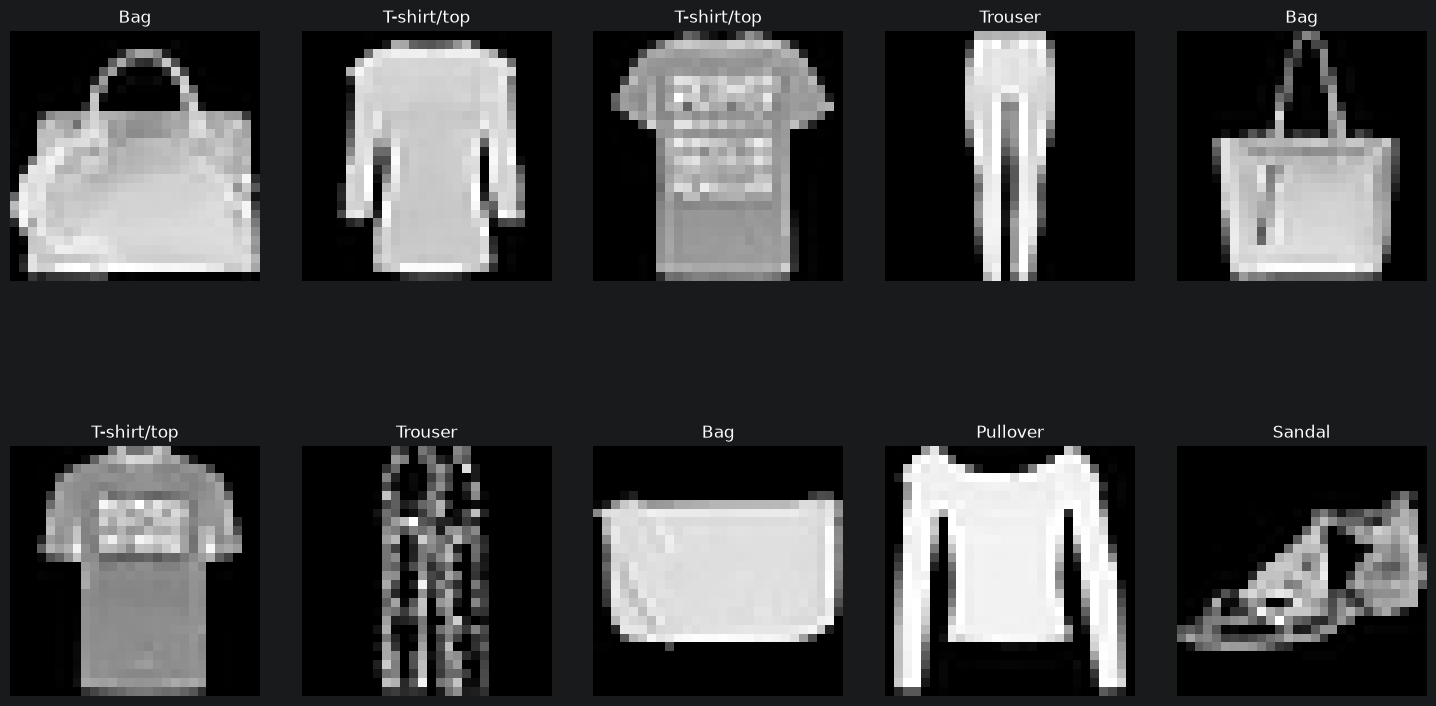

In [6]:
import random

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

indices = random.sample(range(len(x_train)), 10)

plt.figure(figsize=(15, 10))

for i, idx in enumerate(indices):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[idx], cmap="gray", interpolation="nearest", vmin=0, vmax=255)
    plt.title(class_names[y_train[idx]])
    plt.axis("off")

plt.tight_layout(pad=3)
plt.show()

In [7]:
# Normalize pixel values
x_train = x_train / 255.0
x_test = x_test / 255.0

# Check the new pixel range
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [8]:
import tensorflow as tf

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(x_train, y_train, epochs=5, validation_split=0.2)

W0000 00:00:1792037165.726424  309012 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1792037165.996957  309012 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5759 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 12.0a


Epoch 1/5


I0000 00:00:1792037170.423267  329003 cuda_dnn.cc:461] Loaded cuDNN version 92501


1500/1500 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - accuracy: 0.7673 - loss: 0.6473 - val_accuracy: 0.8248 - val_loss: 0.4863
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8364 - loss: 0.4472 - val_accuracy: 0.8466 - val_loss: 0.4317
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8534 - loss: 0.3957 - val_accuracy: 0.8549 - val_loss: 0.3958
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8663 - loss: 0.3637 - val_accuracy: 0.8688 - val_loss: 0.3581
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8714 - loss: 0.3435 - val_accuracy: 0.8651 - val_loss: 0.3557


In [9]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8576 - loss: 0.3828
Test Loss: 0.3828031122684479
Test Accuracy: 0.8575999736785889


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step   


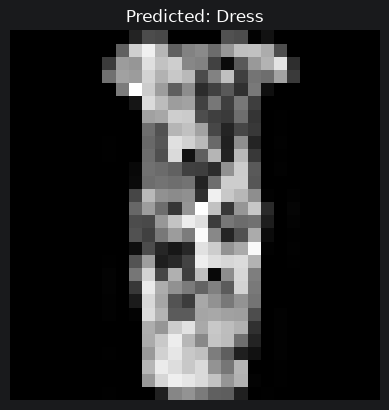

Predicted class: Dress
Actual class: Dress


In [10]:
import matplotlib.pyplot as plt
import numpy as np

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

predictions = model.predict(x_test)

index = 100
predicted_class = np.argmax(predictions[index])

plt.imshow(x_test[index], cmap='gray')
plt.title(f"Predicted: {class_names[predicted_class]}")
plt.axis('off')
plt.show()

print("Predicted class:", class_names[predicted_class])
print("Actual class:", class_names[y_test[index]])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 


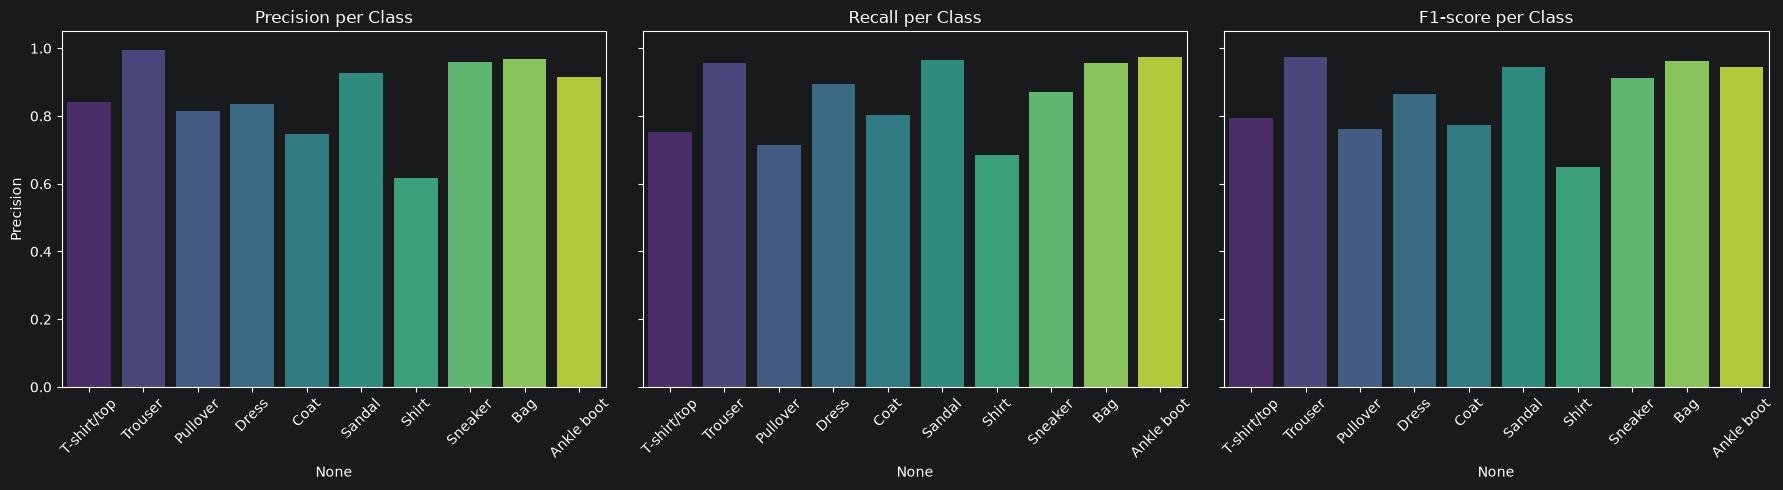

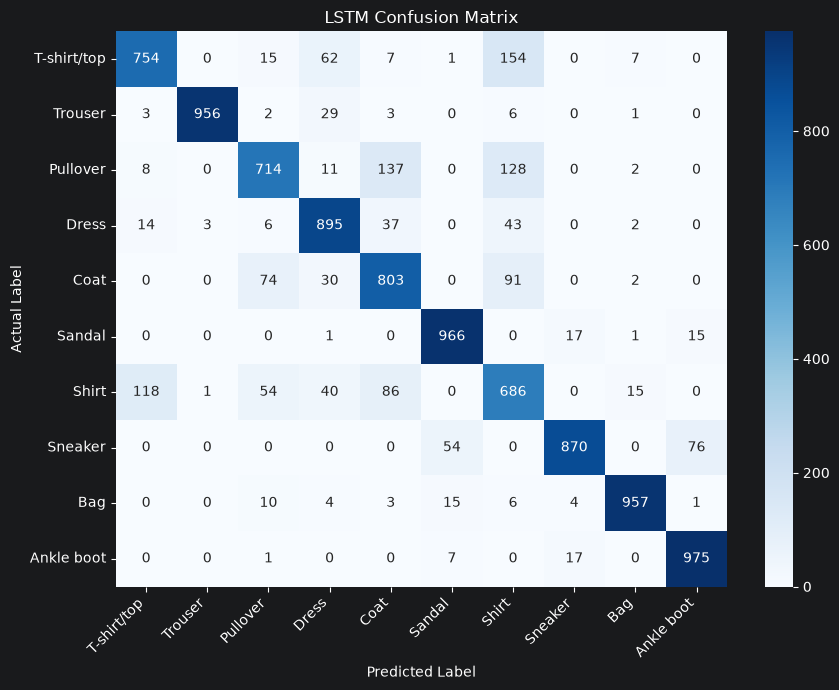

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

# 1. Define class names
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

# 2. Get predictions
y_true = y_test
y_pred = model.predict(x_test).argmax(axis=1)

# 3. Calculate precision, recall, and F1-score
precision, recall, f1, _ = precision_recall_fscore_support(
    y_true, y_pred, zero_division=0
)

df_metrics = pd.DataFrame({
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
}, index=class_names)

# 4. Plot scores for each class
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for i, col in enumerate(df_metrics.columns):
    sns.barplot(
        x=df_metrics.index,
        y=df_metrics[col],
        ax=axes[i],
        hue=df_metrics.index,
        palette='viridis',
        legend=False
    )
    axes[i].set_title(f'{col} per Class')
    axes[i].set_ylim(0, 1.05)
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# 5. Plot confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('LSTM Confusion Matrix')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [12]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

# 2. Normalize pixel values to the range 0–1
x_train = x_train / 255.0
x_test = x_test / 255.0

# 3. Add a channel dimension for CNN
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

# 4. Check the shapes
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28, 1)
Training labels: (60000,)
Testing images: (10000, 28, 28, 1)
Testing labels: (10000,)


In [13]:
model_cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(10, activation='softmax')
])

model_cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_cnn.fit(
    x_train, y_train,
    epochs=5,
    validation_split=0.2
)

Epoch 1/5


I0000 00:00:1792037228.139256  328996 service.cc:153] XLA service 0x118000e0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792037228.139297  328996 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 5070 Laptop GPU, Compute Capability 12.0a (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.25.1)
I0000 00:00:1792037228.198197  328996 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792037228.388974  328996 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_46669__.20


  68/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6048 - loss: 1.1641    

I0000 00:00:1792037231.754346  328996 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8351 - loss: 0.4726 - val_accuracy: 0.8785 - val_loss: 0.3498
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8853 - loss: 0.3260 - val_accuracy: 0.8853 - val_loss: 0.3230
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8984 - loss: 0.2887 - val_accuracy: 0.8942 - val_loss: 0.3009
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9068 - loss: 0.2645 - val_accuracy: 0.8962 - val_loss: 0.2918
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9137 - loss: 0.2452 - val_accuracy: 0.8998 - val_loss: 0.2871


In [14]:
test_loss, test_accuracy = model_cnn.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8924 - loss: 0.3017    
Test Loss: 0.3017285466194153
Test Accuracy: 0.8924000263214111


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step    
             Precision  Recall  F1-score
T-shirt/top      0.809   0.868     0.837
Trouser          0.981   0.983     0.982
Pullover         0.816   0.852     0.834
Dress            0.959   0.803     0.874
Coat             0.815   0.862     0.838
Sandal           0.975   0.975     0.975
Shirt            0.705   0.693     0.699
Sneaker          0.949   0.954     0.952
Bag              0.974   0.973     0.973
Ankle boot       0.962   0.961     0.961


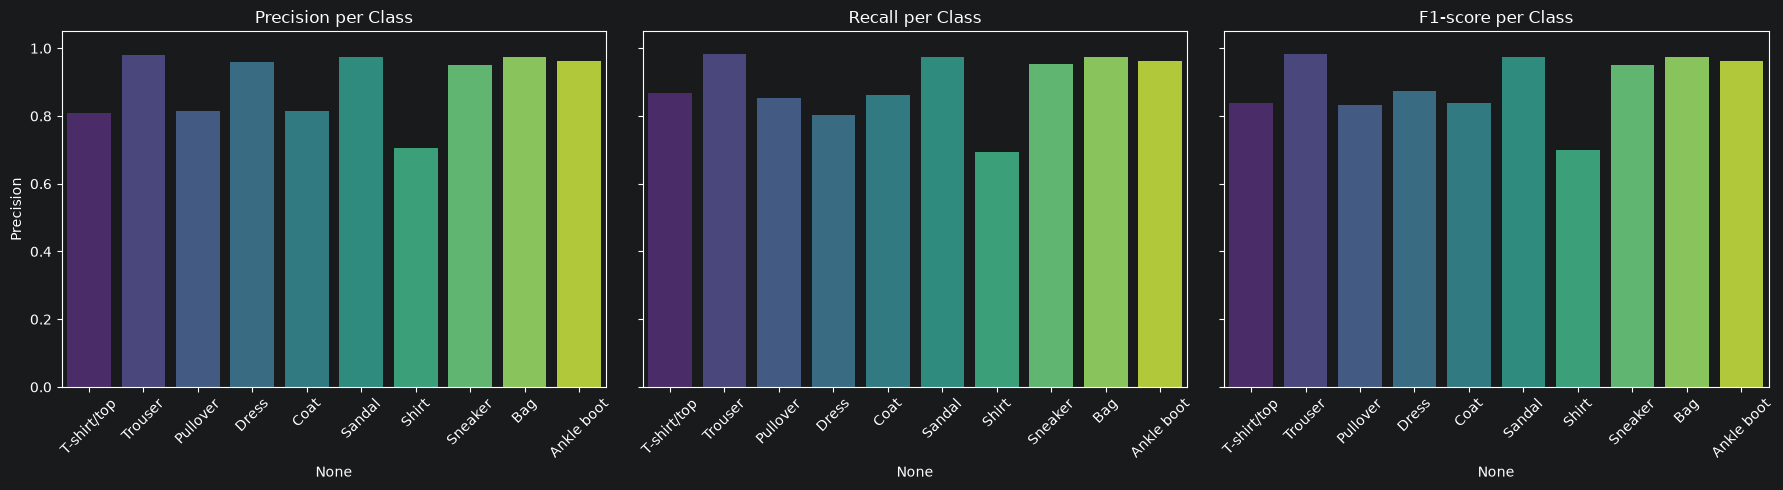

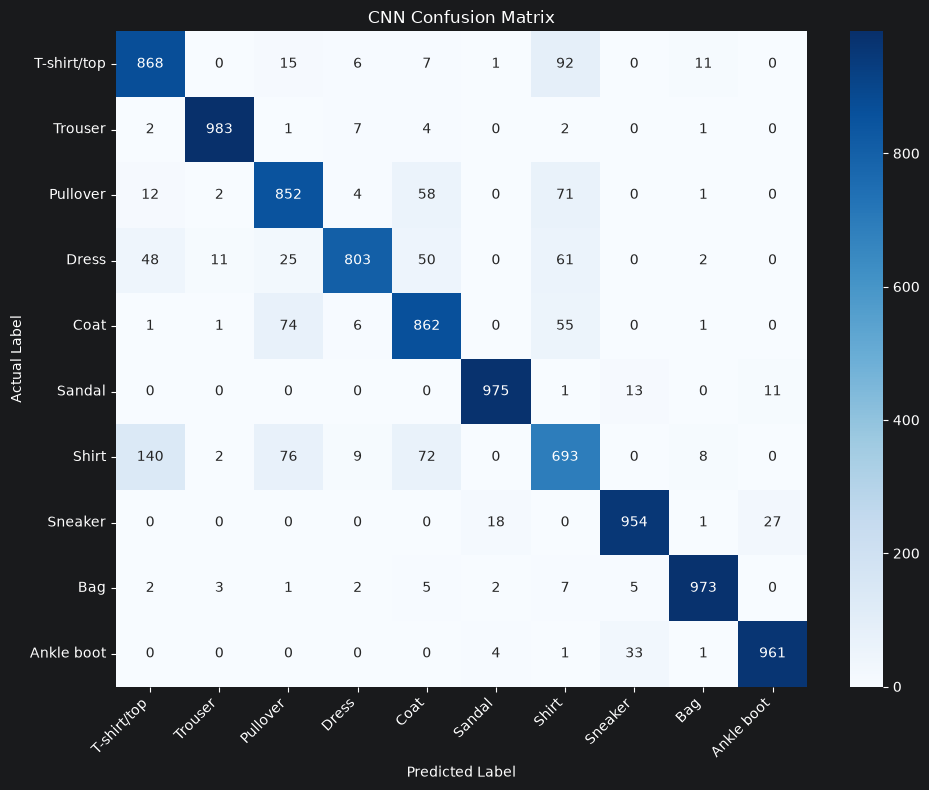

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

# 1. Define class names
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

# 2. Get predicted classes
y_true = y_test
y_pred = model_cnn.predict(x_test).argmax(axis=1)

# 3. Calculate evaluation scores
precision, recall, f1, _ = precision_recall_fscore_support(
    y_true, y_pred, zero_division=0
)

df_metrics = pd.DataFrame({
    'Precision': precision,
    'Recall': recall,
    'F1-score': f1
}, index=class_names)

print(df_metrics.round(3))

# 4. Plot Precision, Recall, and F1-score
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for i, col in enumerate(df_metrics.columns):
    sns.barplot(
        x=df_metrics.index,
        y=df_metrics[col],
        ax=axes[i],
        hue=df_metrics.index,
        palette='viridis',
        legend=False
    )
    axes[i].set_title(f'{col} per Class')
    axes[i].set_ylim(0, 1.05)
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# 5. Plot confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('CNN Confusion Matrix')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()